# Waste Composition (Types of Waste), Nonthaburi Province

**Data:** `data/clean/waste_composition.csv` — results of waste-sorting samples from 6 local governments (Pak Kret City Municipality, Phimonrat Town Municipality, Nonthaburi City Municipality, Khlong Khoi SAO, Bang Si Thong Subdistrict Municipality, Khlong Phra Udom SAO), in kilograms per sample, with the average and percentage of each component

**Questions answered:** what is Nonthaburi's waste made of? What share is **recyclable** or **compostable**? How do the local governments differ?

# องค์ประกอบ (ประเภท) ขยะมูลฝอย จังหวัดนนทบุรี

**ข้อมูล:** `data/clean/waste_composition.csv` — ผลการสุ่มคัดแยกขยะของ 6 อปท. (ทน.ปากเกร็ด, ทม.พิมลราช, ทน.นนทบุรี, อบต.คลองข่อย, ทต.บางสีทอง, อบต.คลองพระอุดม) หน่วยเป็นกิโลกรัมต่อตัวอย่าง พร้อมค่าเฉลี่ยและร้อยละของแต่ละองค์ประกอบ

**คำถามที่ตอบ:** ขยะของนนทบุรีประกอบด้วยอะไรบ้าง? สัดส่วนที่ **รีไซเคิลได้** หรือ **ทำปุ๋ยหมักได้** มีเท่าไร? แต่ละ อปท. ต่างกันอย่างไร?

**Import libraries** — `pandas` handles tabular data (DataFrame) and `numpy` handles numbers/missing values (`np.nan`)

**นำเข้าไลบรารี** — `pandas` ใช้จัดการข้อมูลแบบตาราง (DataFrame) และ `numpy` ใช้คำนวณตัวเลข/จัดการค่าว่าง (`np.nan`)

In [1]:
import pandas as pd
import numpy as np

**Load the waste composition table** — each row is a waste type (food scraps, plastic, etc.), each column is a sampled local government

Note that the last 2 rows are not waste types but summary rows (`รวมมูลฝอยทั้งหมด...` total and `ร้อยละ` percent) — they must be removed before charting

**โหลดตารางองค์ประกอบมูลฝอย** — แต่ละแถวคือประเภทขยะ (เศษอาหาร, พลาสติก ฯลฯ) แต่ละคอลัมน์คือ อปท. ที่สุ่มตัวอย่าง

สังเกตว่า 2 แถวสุดท้ายไม่ใช่ประเภทขยะ แต่เป็นแถวสรุป (`รวมมูลฝอยทั้งหมด...` และ `ร้อยละ`) — ต้องตัดออกก่อนทำกราฟ

In [2]:
df = pd.read_csv('../data/clean/waste_composition.csv')
df

,องค์ประกอบมูลฝอย,ทน.ปากเกร็ด,ทม.พิมลราช,ทน.นนทบุรี,อบต.คลองข่อย,ทต.บางสีทอง,อบต.คลองพระอุดม,ค่าเฉลี่ย (กิโลกรัม),ร้อยละ
0,เศษอาหาร,42.3,39.20,44.7,34.3,45.6,48.8,41.90,39.8
1,มูลฝอยจากสวน,1.8,8.20,7.6,2.0,7.8,9.8,6.20,5.8
2,กระดาษ,6.9,7.70,7.5,13.9,7.0,6.2,8.20,7.7
3,ไม้,0.5,0.70,1.2,1.1,0.6,1.4,0.95,0.9
4,ผ้า,4.8,2.40,5.0,3.6,2.0,4.0,3.80,4.0
5,ยางและหนัง,0.4,1.20,1.2,5.8,3.0,0.2,1.90,1.8
6,ผ้าอ้อม,0.2,6.00,6.1,1.2,4.6,3.6,3.60,3.4
7,พลาสติก,32.9,28.00,24.2,26.5,30.6,27.8,28.50,27.0
8,โฟม,0.5,0.20,0.7,0.3,0.4,0.8,0.50,0.5
9,โลหะและอลูมิเนียม,0.4,0.70,0.5,1.8,0.8,4.8,1.50,1.4


---
# Part 2: Data Visualization

This part turns the cleaned data into several kinds of charts to answer **"what is happening in this data"** across time (yearly/monthly), area (district/local government) and proportions

**The next cell sets up shared chart settings used by every chart:**
- Picks a **Thai font** available on the machine (Tahoma / Thonburi / Leelawadee UI, etc.) so Thai text does not turn into boxes
- Defines a **color palette (PALETTE)** tested for color-vision deficiency, and a fixed **color per district (DIST_COLOR)** — the same district has the same color in every chart and every notebook
- Creates **helper functions** `bar_labels` (numbers on bars), `stacked_bar` (stacked bar chart), `pie_chart` (pie chart)
- Creates a `viz` table, a copy of the data with category columns converted back to text so `groupby` is simple and produces no empty groups

# ส่วนที่ 2: การแสดงผลข้อมูล (Data Visualization)

ส่วนนี้นำข้อมูลที่ทำความสะอาดแล้วมาสร้างกราฟหลายรูปแบบ เพื่อตอบคำถามว่า **"เกิดอะไรขึ้นกับข้อมูลนี้"** ทั้งในมิติ เวลา (รายปี/รายเดือน) พื้นที่ (รายอำเภอ/อปท.) และสัดส่วน

**เซลล์ถัดไปเป็นการตั้งค่ากราฟที่ใช้ร่วมกันทุกกราฟ:**
- เลือก **ฟอนต์ภาษาไทย** ที่มีในเครื่อง (Tahoma / Thonburi / Leelawadee UI ฯลฯ) เพื่อไม่ให้ตัวอักษรไทยกลายเป็นสี่เหลี่ยม
- กำหนด **ชุดสี (PALETTE)** ที่ผ่านการทดสอบสำหรับผู้มีภาวะตาบอดสี และกำหนด **สีประจำอำเภอ (DIST_COLOR)** ให้คงที่ — อำเภอเดียวกันจะเป็นสีเดียวกันในทุกกราฟและทุก notebook
- สร้าง **ฟังก์ชันช่วย** `bar_labels` (ใส่ตัวเลขบนแท่ง), `stacked_bar` (กราฟแท่งซ้อน), `pie_chart` (แผนภูมิวงกลม)
- สร้างตาราง `viz` ซึ่งเป็นสำเนาของข้อมูลที่แปลงคอลัมน์ category กลับเป็นข้อความ เพื่อให้ `groupby` ทำงานง่ายและไม่เกิดกลุ่มว่าง

In [3]:
# ── Chart setup (shared by every chart in this section) ─────────────────
# ── ตั้งค่ากราฟ (ใช้ร่วมกันทุกกราฟในส่วนนี้) ─────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm, to_rgb
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 1) Thai font: pick the first one available on this machine
# 1) ฟอนต์ภาษาไทย: เลือกตัวแรกที่มีในเครื่อง
thai_fonts = ['Tahoma', 'Thonburi', 'Leelawadee UI', 'TH Sarabun New', 'Noto Sans Thai']
available = {f.name for f in fm.fontManager.ttflist}
thai_font = next((f for f in thai_fonts if f in available), 'DejaVu Sans')
plt.rcParams.update({
    'font.family': thai_font, 'axes.unicode_minus': False,
    'figure.dpi': 110, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#bdbcb6', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e8e7e2', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlepad': 12,
    'legend.frameon': False,
})
print(f'ใช้ฟอนต์: {thai_font}')

# 2) Color palette (fixed order — checked for color-vision-deficiency separation)
# 2) ชุดสี (เรียงลำดับคงที่ — ผ่านการตรวจความแตกต่างสำหรับผู้มีภาวะตาบอดสี)
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
GRAY = '#9a9992'
TEXT = '#52514e'
DIST_ORDER = ['เมืองนนทบุรี', 'บางกรวย', 'บางใหญ่', 'บางบัวทอง', 'ไทรน้อย', 'ปากเกร็ด']
DIST_COLOR = dict(zip(DIST_ORDER, PALETTE))           # color per district (fixed across all charts) — สีประจำอำเภอ (คงที่ทุกกราฟ)
MONTHS = ['มกราคม', 'กุมภาพันธ์', 'มีนาคม', 'เมษายน', 'พฤษภาคม', 'มิถุนายน',
          'กรกฎาคม', 'สิงหาคม', 'กันยายน', 'ตุลาคม', 'พฤศจิกายน', 'ธันวาคม']
MONTHS_SHORT = ['ม.ค.', 'ก.พ.', 'มี.ค.', 'เม.ย.', 'พ.ค.', 'มิ.ย.',
                'ก.ค.', 'ส.ค.', 'ก.ย.', 'ต.ค.', 'พ.ย.', 'ธ.ค.']
SEQ_CMAP = LinearSegmentedColormap.from_list('seq_blue', ['#eef4fc', '#86b6ef', '#2a78d6', '#104281'])
DIV_CMAP = LinearSegmentedColormap.from_list('div_blue_orange', ['#2a78d6', '#f0efec', '#eb6834'])
fmt_k = mtick.FuncFormatter(lambda x, _: f'{x:,.0f}')


def bar_labels(ax, bars, fmt='{:,.0f}', horizontal=False, fontsize=9):
    """Write the value at the end of each bar — เขียนตัวเลขกำกับที่ปลายแท่ง"""
    for b in bars:
        v = b.get_width() if horizontal else b.get_height()
        if horizontal:
            ax.text(v, b.get_y() + b.get_height() / 2, '  ' + fmt.format(v),
                    va='center', ha='left', fontsize=fontsize, color=TEXT)
        else:
            ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v),
                    ha='center', va='bottom', fontsize=fontsize, color=TEXT)


def stacked_bar(ax, table, colors=None, horizontal=False):
    """Stacked bar chart: table index = main axis, columns = stacked groups; returns each bar's total — กราฟแท่งซ้อน: index ของ table = แกนหลัก, columns = กลุ่มที่ซ้อนกัน; คืนค่ายอดรวมของแต่ละแท่ง"""
    if colors is None:
        colors = [DIST_COLOR.get(c, PALETTE[i % len(PALETTE)]) for i, c in enumerate(table.columns)]
    pos = np.arange(len(table))
    base = np.zeros(len(table))
    for c, color in zip(table.columns, colors):
        vals = table[c].fillna(0).to_numpy(dtype=float)
        if horizontal:
            ax.barh(pos, vals, left=base, color=color, edgecolor='white', linewidth=1, height=0.65, label=str(c))
        else:
            ax.bar(pos, vals, bottom=base, color=color, edgecolor='white', linewidth=1, width=0.65, label=str(c))
        base += vals
    if horizontal:
        ax.set_yticks(pos, [str(i) for i in table.index]); ax.grid(axis='y', visible=False)
    else:
        ax.set_xticks(pos, [str(i) for i in table.index]); ax.grid(axis='x', visible=False)
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    return base


def end_labels(ax, x, items, min_gap_frac=0.045):
    """Labels at the end of lines (items = [(name, y value)]) — spaced apart automatically so they do not overlap — ชื่อกำกับที่ปลายเส้น (items = [(ชื่อ, ค่า y)]) — ขยับห่างกันอัตโนมัติไม่ให้ทับกัน"""
    lo, hi = ax.get_ylim()
    gap = (hi - lo) * min_gap_frac
    items = sorted(items, key=lambda t: t[1])
    ys = [y for _, y in items]
    for i in range(1, len(ys)):
        ys[i] = max(ys[i], ys[i - 1] + gap)
    for (lab, _), y in zip(items, ys):
        ax.annotate(lab, (x, y), xytext=(8, 0), textcoords='offset points', va='center',
                    fontsize=9, color=TEXT, annotation_clip=False)


def ref_line(ax, value, label, axis='y'):
    """Reference line (average/target) with its label outside the plot area so it does not cover bars — เส้นอ้างอิง (ค่าเฉลี่ย/เป้าหมาย) พร้อมป้ายกำกับนอกพื้นที่กราฟ ไม่ทับแท่ง"""
    if axis == 'y':
        ax.axhline(value, color=TEXT, linewidth=1, linestyle='--')
        ax.text(1.01, value, label, transform=ax.get_yaxis_transform(), va='center', ha='left', fontsize=9, color=TEXT)
    else:
        ax.axvline(value, color=TEXT, linewidth=1, linestyle='--')
        ax.text(value, 1.01, label, transform=ax.get_xaxis_transform(), va='bottom', ha='center', fontsize=9, color=TEXT)


def _ink(color):
    r, g, b = to_rgb(color)
    return '#0b0b0b' if (0.299 * r + 0.587 * g + 0.114 * b) > 0.6 else 'white'


def pie_chart(ax, values, labels, colors=None, title='', min_pct=4):
    """Pie chart: % inside slices that are big enough, name + % of every slice in the legend — แผนภูมิวงกลม: % ในชิ้นที่ใหญ่พอ, ชื่อ + % ทุกชิ้นอยู่ใน legend"""
    values = np.asarray(values, dtype=float)
    labels = [str(l) for l in labels]
    colors = colors or PALETTE[:len(values)]
    total = values.sum()
    wedges, _, autotexts = ax.pie(
        values, colors=colors, startangle=90, counterclock=False, pctdistance=0.7,
        autopct=lambda p: f'{p:.1f}%' if p >= min_pct else '',
        wedgeprops=dict(edgecolor='white', linewidth=2))
    for w, t in zip(wedges, autotexts):
        t.set_color(_ink(w.get_facecolor())); t.set_fontsize(10); t.set_fontweight('bold')
    ax.legend(wedges, [f'{l}  {v:,.0f} ({v / total * 100:.1f}%)' for l, v in zip(labels, values)],
              loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10)
    ax.set_title(title)
    ax.axis('equal')

ใช้ฟอนต์: Tahoma


**Prepare the data for charts**
- Remove summary rows containing "รวม" (total) or "ร้อยละ" (percent), leaving the 15 waste types
- Group the waste types into 4 main groups by how they are managed:
  - **Organic waste** (compost/biogas): food scraps, garden waste, wood
  - **Recyclable waste** (can be sold): paper, plastic, metal & aluminium, glass
  - **Hazardous/infectious waste** (needs special disposal): hazardous waste, electronic waste, infectious waste
  - **General waste** (mostly landfilled/incinerated): textiles, rubber & leather, diapers, foam, other

**เตรียมข้อมูลสำหรับกราฟ**
- ตัดแถวสรุปที่มีคำว่า "รวม" หรือ "ร้อยละ" ออก เหลือเฉพาะ 15 ประเภทขยะ
- จัดกลุ่มประเภทขยะเป็น 4 กลุ่มใหญ่ตามแนวทางการจัดการ:
  - **ขยะอินทรีย์** (ทำปุ๋ยหมัก/ก๊าซชีวภาพได้): เศษอาหาร, มูลฝอยจากสวน, ไม้
  - **ขยะรีไซเคิล** (ขายได้): กระดาษ, พลาสติก, โลหะและอลูมิเนียม, แก้ว
  - **ขยะอันตราย/ติดเชื้อ** (ต้องแยกกำจัดพิเศษ): ของเสียอันตราย, ซากอิเล็กทรอนิกส์, มูลฝอยติดเชื้อ
  - **ขยะทั่วไป** (ส่วนใหญ่ต้องฝังกลบ/เผา): ผ้า, ยางและหนัง, ผ้าอ้อม, โฟม, อื่นๆ

In [4]:
comp_col = 'องค์ประกอบมูลฝอย'
apt_cols = list(df.columns[1:7])                       # the 6 sampled local governments — 6 อปท. ที่สุ่มตัวอย่าง
comp = df[~df[comp_col].str.contains('รวม|ร้อยละ', na=False)].copy().set_index(comp_col)

GROUPS = {
    'ขยะอินทรีย์': ['เศษอาหาร', 'มูลฝอยจากสวน', 'ไม้'],
    'ขยะรีไซเคิล': ['กระดาษ', 'พลาสติก', 'โลหะและอลูมิเนียม', 'แก้ว'],
    'ขยะอันตราย/ติดเชื้อ': ['ของเสียอันตราย', 'ซากอิเล็กทรอนิกส์', 'มูลฝอยติดเชื้อ'],
    'ขยะทั่วไป': ['ผ้า', 'ยางและหนัง', 'ผ้าอ้อม', 'โฟม', 'อื่นๆ'],
}
GROUP_COLOR = dict(zip(GROUPS, [PALETTE[2], PALETTE[0], PALETTE[7], GRAY]))
item_group = {item: g for g, items in GROUPS.items() for item in items}
comp['กลุ่ม'] = comp.index.map(item_group)
comp[['ร้อยละ', 'กลุ่ม']].sort_values('ร้อยละ', ascending=False)

,ร้อยละ,กลุ่ม
องค์ประกอบมูลฝอย,,
เศษอาหาร,39.8,ขยะอินทรีย์
พลาสติก,27.0,ขยะรีไซเคิล
กระดาษ,7.7,ขยะรีไซเคิล
มูลฝอยจากสวน,5.8,ขยะอินทรีย์
ผ้า,4.0,ขยะทั่วไป
แก้ว,3.5,ขยะรีไซเคิล
ผ้าอ้อม,3.4,ขยะทั่วไป
ยางและหนัง,1.8,ขยะทั่วไป
โลหะและอลูมิเนียม,1.4,ขยะรีไซเคิล


### 2.1 Horizontal bar chart: share of each waste type (% average of 6 local governments), largest to smallest
**How to read it:** the bar color shows the group (green = organic, blue = recyclable, red = hazardous, gray = general) — shows which types make up most of the bin

### 2.1 กราฟแท่งแนวนอน: สัดส่วนแต่ละประเภทขยะ (% เฉลี่ย 6 อปท.) เรียงจากมากไปน้อย
**วิธีอ่าน:** สีของแท่งบอกกลุ่ม (เขียว = อินทรีย์, น้ำเงิน = รีไซเคิล, แดง = อันตราย, เทา = ทั่วไป) — ใช้ดูว่าประเภทใดเป็นส่วนใหญ่ของถังขยะ

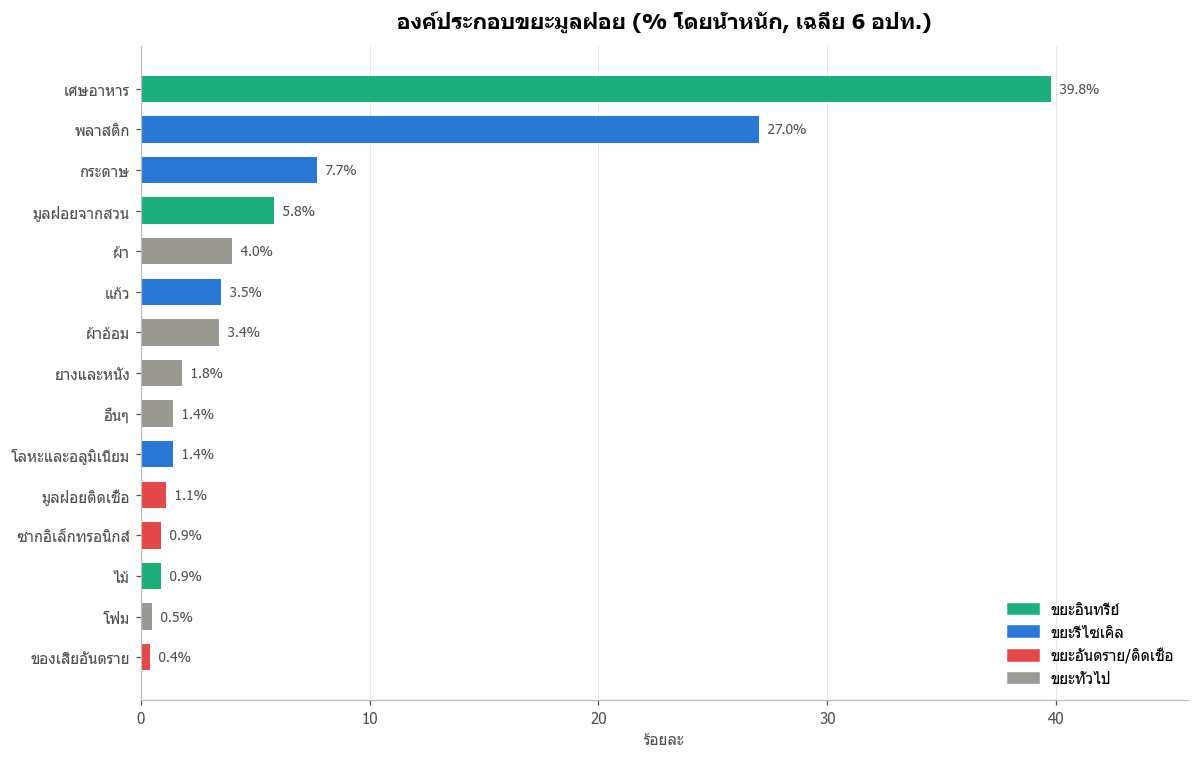

In [5]:
ranked = comp.sort_values('ร้อยละ')
fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(ranked.index, ranked['ร้อยละ'], color=[GROUP_COLOR[g] for g in ranked['กลุ่ม']], height=0.65)
bar_labels(ax, bars, fmt='{:.1f}%', horizontal=True)
ax.set_xlim(0, ranked['ร้อยละ'].max() * 1.15); ax.grid(axis='y', visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLOR.values()]
ax.legend(handles, GROUP_COLOR.keys(), loc='lower right')
ax.set_title('องค์ประกอบขยะมูลฝอย (% โดยน้ำหนัก, เฉลี่ย 6 อปท.)'); ax.set_xlabel('ร้อยละ')
plt.tight_layout(); plt.show()

### 2.2 Pie chart: waste composition
**What it does:** types with less than 4% are merged into "อื่นๆ (รวมส่วนน้อย)" (other, small shares) so the pie has no slices too small to read (at most 6 slices)

**How to read it:** food scraps and plastic together are the largest share — these two types are the main targets for waste reduction

### 2.2 แผนภูมิวงกลม: องค์ประกอบขยะมูลฝอย
**ทำอะไร:** ประเภทที่มีสัดส่วนน้อยกว่า 4% ถูกรวมเป็น "อื่นๆ (รวมส่วนน้อย)" เพื่อให้วงกลมไม่มีชิ้นเล็กเกินอ่าน (ไม่เกิน 6 ชิ้น)

**วิธีอ่าน:** เศษอาหารและพลาสติกรวมกันเป็นสัดส่วนใหญ่ที่สุด — สองประเภทนี้คือเป้าหมายหลักของการลดขยะ

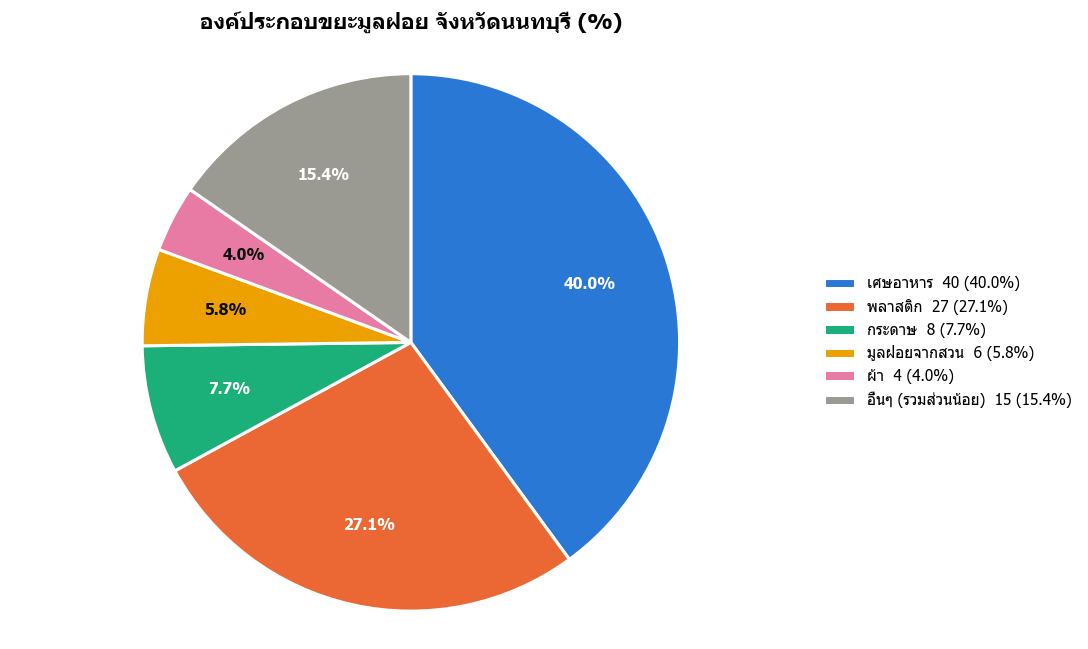

ประเภทที่ถูกรวมเป็น "อื่นๆ": แก้ว, ผ้าอ้อม, ยางและหนัง, โลหะและอลูมิเนียม, อื่นๆ, มูลฝอยติดเชื้อ, ไม้, ซากอิเล็กทรอนิกส์, โฟม, ของเสียอันตราย


In [6]:
THRESHOLD = 4.0
pct = comp['ร้อยละ'].sort_values(ascending=False)
big, small = pct[pct >= THRESHOLD], pct[pct < THRESHOLD]
plot_pct = pd.concat([big, pd.Series({'อื่นๆ (รวมส่วนน้อย)': small.sum()})])
fig, ax = plt.subplots(figsize=(10, 6))
pie_chart(ax, plot_pct.values, plot_pct.index,
          colors=PALETTE[:len(big)] + [GRAY], title='องค์ประกอบขยะมูลฝอย จังหวัดนนทบุรี (%)')
plt.tight_layout(); plt.show()
print('ประเภทที่ถูกรวมเป็น "อื่นๆ":', ', '.join(small.index))

### 2.3 Pie chart: share by the 4 management groups
**How to read it:** answers a policy question — with perfect sorting, what % of waste (**organic + recyclable**) would not need to go to landfill

### 2.3 แผนภูมิวงกลม: สัดส่วนตาม 4 กลุ่มการจัดการ
**วิธีอ่าน:** ตอบคำถามเชิงนโยบาย — ถ้าคัดแยกได้สมบูรณ์ ขยะ **อินทรีย์ + รีไซเคิล** สามารถไม่ต้องส่งไปฝังกลบได้กี่ %

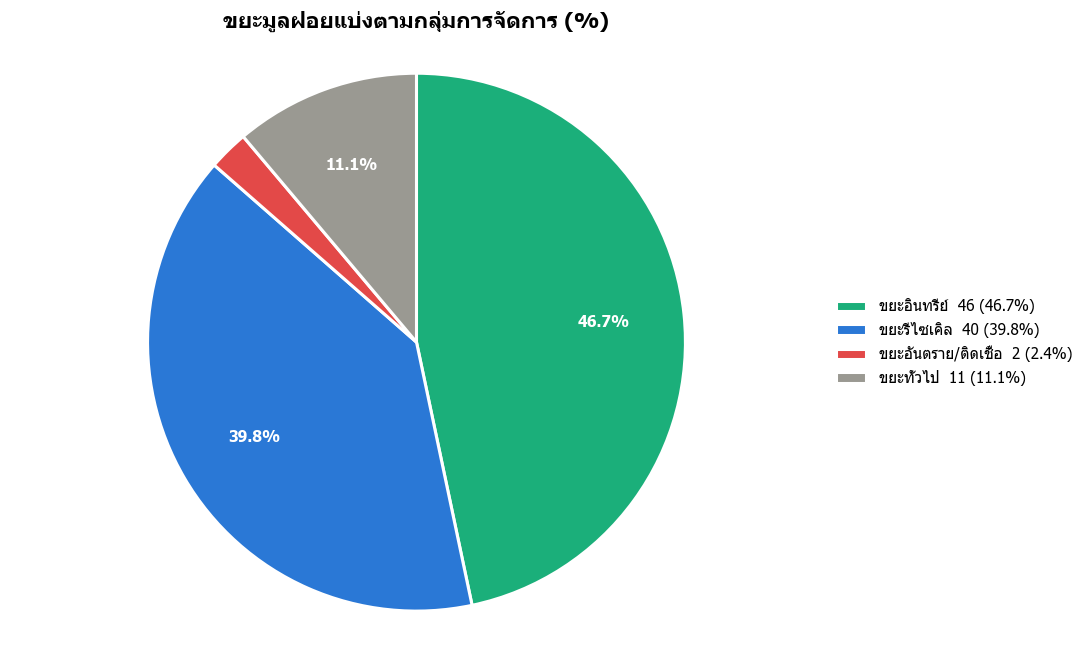

ขยะที่นำไปใช้ประโยชน์ได้ (อินทรีย์ + รีไซเคิล) = 86.1%


In [7]:
grp = comp.groupby('กลุ่ม')['ร้อยละ'].sum().reindex(GROUPS.keys())
fig, ax = plt.subplots(figsize=(10, 6))
pie_chart(ax, grp.values, grp.index, colors=[GROUP_COLOR[g] for g in grp.index],
          title='ขยะมูลฝอยแบ่งตามกลุ่มการจัดการ (%)')
plt.tight_layout(); plt.show()
print(f"ขยะที่นำไปใช้ประโยชน์ได้ (อินทรีย์ + รีไซเคิล) = {grp['ขยะอินทรีย์'] + grp['ขยะรีไซเคิล']:.1f}%")

### 2.4 Heatmap: amount of each waste type × local government (kilograms)
**How to read it:** rows = waste types, columns = local governments, darker = more. Use it to find differences between areas, e.g. a local government with unusually high plastic or electronic waste

### 2.4 Heatmap: ปริมาณขยะแต่ละประเภท × อปท. (กิโลกรัม)
**วิธีอ่าน:** แถว = ประเภทขยะ, คอลัมน์ = อปท., สีเข้ม = ปริมาณมาก ใช้หาความแตกต่างระหว่างพื้นที่ เช่น อปท. ที่มีขยะพลาสติกหรือขยะอิเล็กทรอนิกส์สูงผิดปกติ

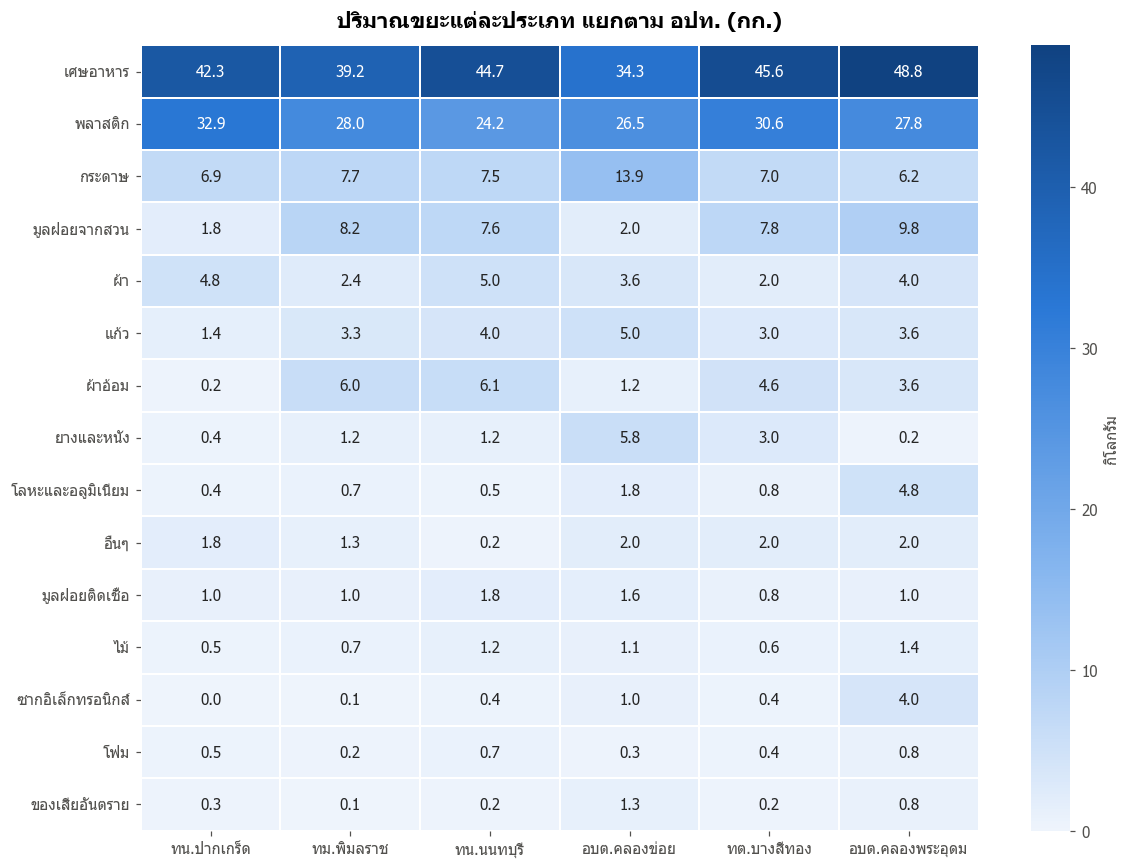

In [8]:
heat = comp.sort_values('ร้อยละ', ascending=False)[apt_cols].astype(float)
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(heat, annot=True, fmt='.1f', cmap=SEQ_CMAP, linewidths=1, linecolor='white',
            cbar_kws={'label': 'กิโลกรัม'}, ax=ax)
ax.set_title('ปริมาณขยะแต่ละประเภท แยกตาม อปท. (กก.)')
ax.set_xlabel(''); ax.set_ylabel('')
ax.tick_params(axis='y', rotation=0)
plt.tight_layout(); plt.show()

### 2.5 100% stacked bar chart: share of the 4 waste groups in each local government
**What it does:** sums the kilograms of each group per local government and converts them to % of that local government (every bar is 100% long)

**How to read it:** compares "composition" regardless of sample size — local governments with a long green part suit composting programs, those with a long blue part suit recycling waste banks

### 2.5 กราฟแท่งซ้อน 100%: สัดส่วน 4 กลุ่มขยะในแต่ละ อปท.
**ทำอะไร:** รวมกิโลกรัมของแต่ละกลุ่มใน อปท. แล้วแปลงเป็น % ของ อปท. นั้น (ทุกแท่งยาว 100%)

**วิธีอ่าน:** เทียบ "องค์ประกอบ" ได้โดยไม่ขึ้นกับขนาดตัวอย่าง — อปท. ที่ส่วนสีเขียวยาวเหมาะกับโครงการปุ๋ยหมัก ส่วนที่สีน้ำเงินยาวเหมาะกับธนาคารขยะรีไซเคิล

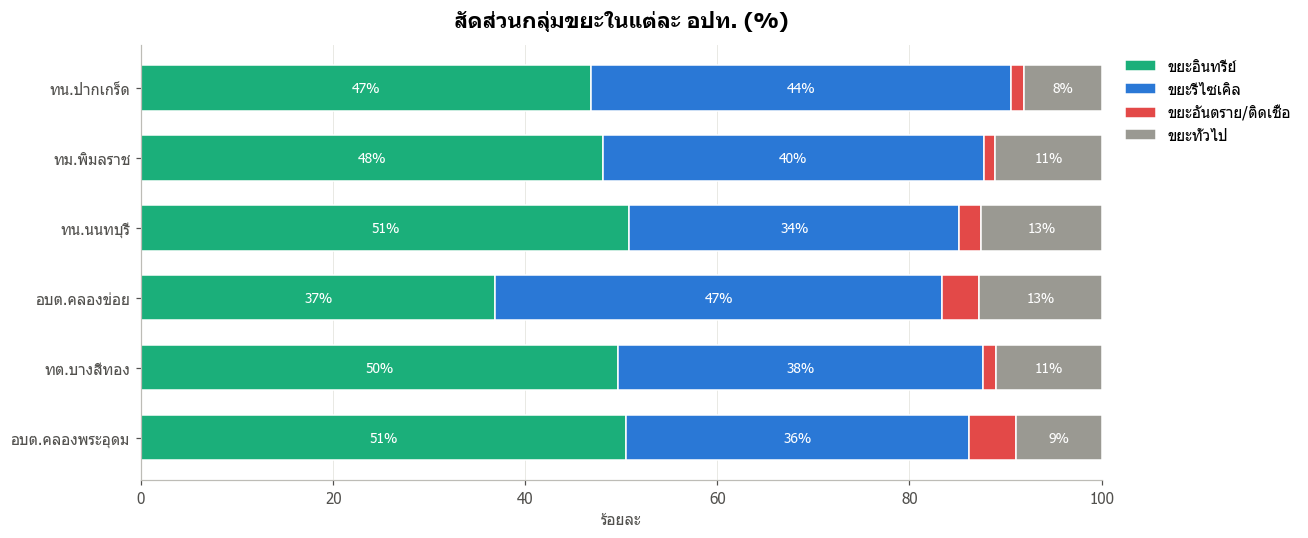

กลุ่ม,ขยะอินทรีย์,ขยะรีไซเคิล,ขยะอันตราย/ติดเชื้อ,ขยะทั่วไป
ทน.ปากเกร็ด,46.8,43.7,1.4,8.1
ทม.พิมลราช,48.1,39.7,1.1,11.1
ทน.นนทบุรี,50.8,34.4,2.3,12.5
อบต.คลองข่อย,36.9,46.5,3.8,12.7
ทต.บางสีทอง,49.6,38.1,1.3,11.0
อบต.คลองพระอุดม,50.5,35.7,4.9,8.9


In [9]:
grp_apt = comp.groupby('กลุ่ม')[apt_cols].sum().reindex(GROUPS.keys())
grp_pct = (grp_apt / grp_apt.sum() * 100).T
fig, ax = plt.subplots(figsize=(12, 5))
stacked_bar(ax, grp_pct, colors=[GROUP_COLOR[g] for g in grp_pct.columns], horizontal=True)
for i, (apt, row) in enumerate(grp_pct.iterrows()):
    left = 0
    for g, v in row.items():
        if v >= 6:
            ax.text(left + v / 2, i, f'{v:.0f}%', ha='center', va='center', fontsize=9, color=_ink(GROUP_COLOR[g]))
        left += v
ax.set_xlim(0, 100); ax.invert_yaxis()
ax.set_title('สัดส่วนกลุ่มขยะในแต่ละ อปท. (%)'); ax.set_xlabel('ร้อยละ')
plt.tight_layout(); plt.show()
grp_pct.round(1)

---
## Key Findings

1. **Food scraps (39.8%) and plastic (27.0%) together make up two thirds of all waste** — the main targets of waste-reduction policy
2. **Organic + recyclable waste ≈ 86.5%** — with perfect sorting, most waste would not need to go to landfill (it could be composted or sold for recycling)
3. **Hazardous and infectious waste is only ~2.4%**, but it must be collected separately because it is dangerous to health and the environment
4. **Local governments differ noticeably** — e.g. Khlong Khoi SAO has high paper (13.9 kg) and more rubber/leather than others, and Khlong Phra Udom SAO has more electronic waste and metal than others

## สรุปข้อค้นพบ

1. **เศษอาหาร (39.8%) และพลาสติก (27.0%) รวมกันเป็น 2 ใน 3 ของขยะทั้งหมด** — เป็นเป้าหมายหลักของนโยบายลดขยะ
2. **ขยะอินทรีย์ + ขยะรีไซเคิล ≈ 86.5%** — ถ้าคัดแยกได้สมบูรณ์ ขยะส่วนใหญ่ไม่จำเป็นต้องไปฝังกลบ (ทำปุ๋ยหมัก/ขายรีไซเคิลได้)
3. **ขยะอันตรายและติดเชื้อมีเพียง ~2.4%** แต่ต้องแยกเก็บเพราะอันตรายต่อสุขภาพและสิ่งแวดล้อม
4. **แต่ละ อปท. ต่างกันพอสมควร** — เช่น อบต.คลองข่อยมีกระดาษสูง (13.9 กก.) และยาง/หนังสูงกว่าที่อื่น, อบต.คลองพระอุดมมีซากอิเล็กทรอนิกส์และโลหะสูงกว่าที่อื่น